In [39]:
import pandas as pd

print(pd.__version__)

3.0.5


In [40]:
df = pd.read_csv("../data/raw/Reviews.csv")

In [41]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [42]:
df.shape

(568454, 10)

In [43]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


# Data Dictionary

| Column | Description | Data Type | Role |
|---|---|---|---|
| Id | Unique identifier for the review record | Integer | Identifier |
| ProductId | Identifier of the reviewed product | String | Product information |
| UserId | Identifier of the reviewer | String | User information |
| ProfileName | Name associated with the reviewer profile | String | User information |
| HelpfulnessNumerator | Number of users who found the review helpful | Integer | Review quality |
| HelpfulnessDenominator | Total number of users who rated the review's helpfulness | Integer | Review quality |
| Score | Product rating given by the reviewer, from 1 to 5 | Integer | Target / rating |
| Time | Unix timestamp representing when the review was created | Integer | Time |
| Summary | Short summary/title written by the reviewer | String | Text feature |
| Text | Full review written by the reviewer | String | Primary text feature |

 **Note:** HelpfulnessNumerator and HelpfulnessDenominator are only meaningful together as a ratio (helpfulness_ratio) — individually they don't indicate review quality

In [45]:
df.dtypes

Id                        int64
ProductId                   str
UserId                      str
ProfileName                 str
HelpfulnessNumerator      int64
HelpfulnessDenominator    int64
Score                     int64
Time                      int64
Summary                     str
Text                        str
dtype: object

In [46]:
df.nunique()

Id                        568454
ProductId                  74258
UserId                    256059
ProfileName               218415
HelpfulnessNumerator         231
HelpfulnessDenominator       234
Score                          5
Time                        3168
Summary                   295742
Text                      393579
dtype: int64

In [47]:
df["Score"].value_counts().sort_index()

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64

# 3. Data Quality Checks

In [48]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [49]:
df.isnull().sum().sort_values(ascending=False)

Summary                   27
ProfileName               26
ProductId                  0
Id                         0
HelpfulnessNumerator       0
UserId                     0
HelpfulnessDenominator     0
Score                      0
Time                       0
Text                       0
dtype: int64

In [50]:
# True duplicate check: same user, same time, same review text
dup_count = df.duplicated(subset=['UserId', 'Time', 'Text']).sum()
print('True duplicates found:', dup_count)

# Drop duplicates, keep the first occurrence
before = len(df)
df = df.drop_duplicates(subset=['UserId', 'Time', 'Text'], keep='first')
print('Rows before:', before, '-> after dedup:', len(df))

# Remove rows where helpfulness data is broken (numerator > denominator)
bad = df[df['HelpfulnessNumerator'] > df['HelpfulnessDenominator']]
print('Broken helpfulness rows:', len(bad))
df = df[~df.index.isin(bad.index)]
print('Final clean row count:', len(df))

True duplicates found: 174562
Rows before: 568454 -> after dedup: 393892
Broken helpfulness rows: 2
Final clean row count: 393890


In [51]:
df["Text"].nunique()

393577

In [52]:
df["Score"].value_counts().sort_index()
df["Score"].min(), df["Score"].max()

(np.int64(1), np.int64(5))

In [53]:
df[~df["Score"].isin([1, 2, 3, 4, 5])].shape

(0, 10)

In [54]:
df[["HelpfulnessNumerator", "HelpfulnessDenominator"]].describe()

,HelpfulnessNumerator,HelpfulnessDenominator
count,393890.000000,393890.000000
mean,1.734497,2.204864
std,6.872626,7.535147
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,1.000000
75%,2.000000,2.000000
max,866.000000,923.000000


In [55]:
(df["HelpfulnessNumerator"] > df["HelpfulnessDenominator"]).sum()


np.int64(0)

In [56]:
df["HelpfulnessDenominator"].value_counts().head(10)

HelpfulnessDenominator
0    184612
1     78460
2     42765
3     24303
4     16038
5     10573
6      7352
7      5369
8      3998
9      3143
Name: count, dtype: int64

# 4. Feature Engineering

In [57]:
df["date"] = pd.to_datetime(df["Time"], unit="s")
df[["Time", "date"]].head()

,Time,date
0,1303862400,2011-04-27
1,1346976000,2012-09-07
2,1219017600,2008-08-18
3,1307923200,2011-06-13
4,1350777600,2012-10-21


In [58]:
df["review_year"] = df["date"].dt.year
df["review_month"] = df["date"].dt.month
df[["date", "review_year", "review_month"]].head()

,date,review_year,review_month
0,2011-04-27,2011,4
1,2012-09-07,2012,9
2,2008-08-18,2008,8
3,2011-06-13,2011,6
4,2012-10-21,2012,10


In [59]:
df["review_length"] = df["Text"].fillna("").str.len()
df["review_length"].describe()

count    393890.000000
mean        434.312874
std         433.678682
min          12.000000
25%         182.000000
50%         304.000000
75%         527.000000
max       21409.000000
Name: review_length, dtype: float64

In [60]:
df["summary_length"] = df["Summary"].fillna("").str.len()
df["summary_length"].describe()

count    393890.000000
mean         23.385212
std          13.980563
min           0.000000
25%          13.000000
50%          20.000000
75%          30.000000
max         128.000000
Name: summary_length, dtype: float64

In [61]:
df["helpfulness_ratio"] = (
    df["HelpfulnessNumerator"]
    / df["HelpfulnessDenominator"].replace(0, pd.NA)
)
df["helpfulness_ratio"].describe()
df[[
    "HelpfulnessNumerator",
    "HelpfulnessDenominator",
    "helpfulness_ratio"
]].head(10)

,HelpfulnessNumerator,HelpfulnessDenominator,helpfulness_ratio
0,1,1,1.0
1,0,0,<NA>
2,1,1,1.0
3,3,3,1.0
4,0,0,<NA>
5,0,0,<NA>
6,0,0,<NA>
7,0,0,<NA>
8,1,1,1.0
9,0,0,<NA>


In [62]:
# Derive sentiment_label from Score (1-2: negative, 3: neutral, 4-5: positive)
def assign_sentiment(score):
    if score > 3:
        return "positive"
    elif score < 3:
        return "negative"
    else:
        return "neutral"

df["sentiment_label"] = df["Score"].apply(assign_sentiment)

# Optional: Fill NA helpfulness ratio with 0.0 for easier numerical modeling later
df["helpfulness_ratio"] = df["helpfulness_ratio"].fillna(0.0)

# Save processed dataframe
df.to_csv("../data/processed/reviews_cleaned.csv", index=False)

# 5. Exploratory Data Analysis

In [63]:
import pandas as pd
import matplotlib.pyplot as plt

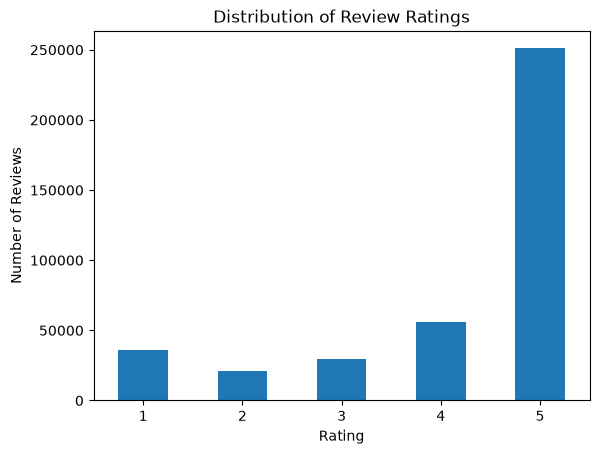

In [64]:
score_counts = df["Score"].value_counts().sort_index()

score_counts.plot(kind="bar")

plt.title("Distribution of Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

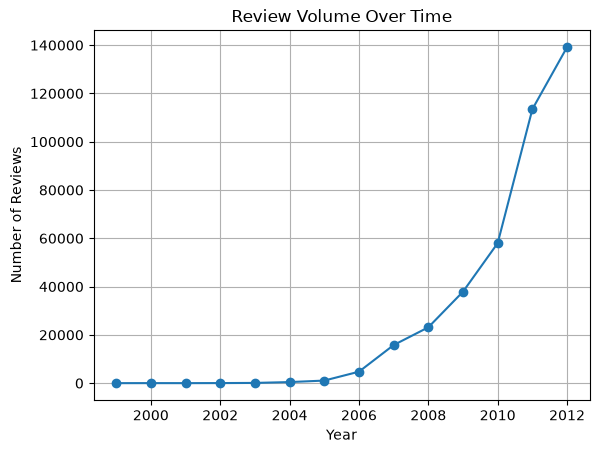

In [73]:
reviews_by_year = df.groupby("review_year").size()

reviews_by_year
reviews_by_year.plot(kind="line", marker="o")

plt.title("Review Volume Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")
plt.grid(True)
plt.show()

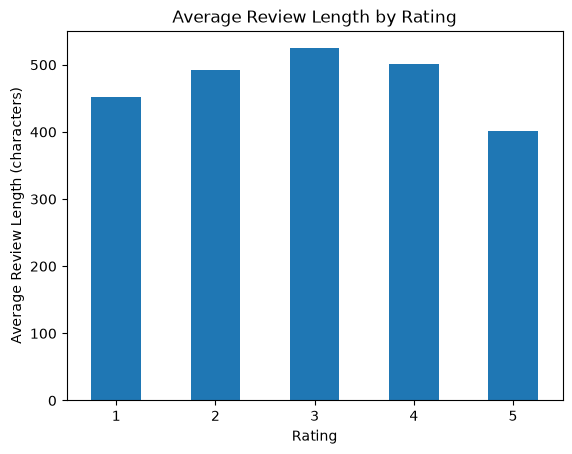

In [66]:
df.groupby("Score")["review_length"].mean()
df.groupby("Score")["review_length"].mean().plot(kind="bar")

plt.title("Average Review Length by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Review Length (characters)")
plt.xticks(rotation=0)
plt.show()

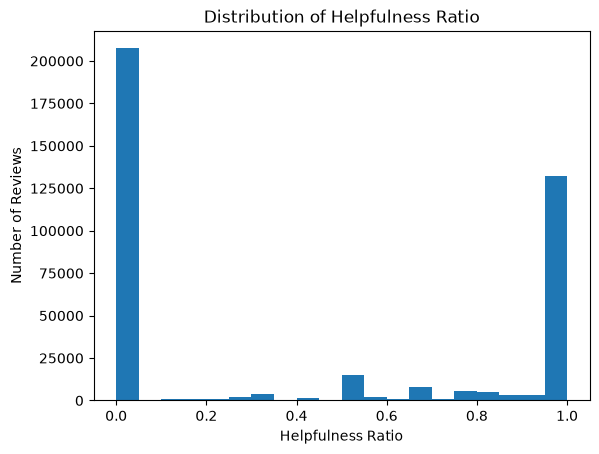

In [67]:
df["helpfulness_ratio"].describe()
df["helpfulness_ratio"].dropna().plot(kind="hist", bins=20)

plt.title("Distribution of Helpfulness Ratio")
plt.xlabel("Helpfulness Ratio")
plt.ylabel("Number of Reviews")
plt.show()

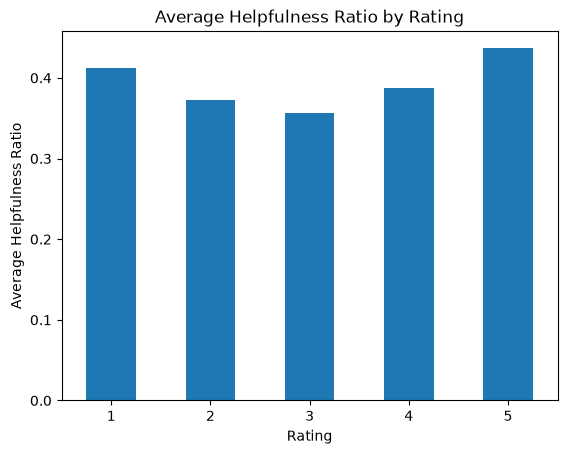

In [68]:
df.groupby("Score")["helpfulness_ratio"].mean()
df.groupby("Score")["helpfulness_ratio"].mean().plot(kind="bar")

plt.title("Average Helpfulness Ratio by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Helpfulness Ratio")
plt.xticks(rotation=0)
plt.show()

Insight 1 — Rating distribution

In [69]:
df["Score"].value_counts(normalize=True).sort_index() * 100

Score
1     9.216279
2     5.280916
3     7.557440
4    14.239001
5    63.706365
Name: proportion, dtype: float64

Insight 2 — Time trend

In [70]:
df.groupby("review_year").size()

review_year
1999         4
2000        17
2001         8
2002        33
2003        99
2004       445
2005      1069
2006      4748
2007     15778
2008     23129
2009     37891
2010     58003
2011    113487
2012    139179
dtype: int64

Insight 3 — Review length

In [71]:
df.groupby("Score")["review_length"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Score,,,,
1,451.834499,332.0,12,11861
2,492.957790,361.0,33,9295
3,524.293604,376.0,32,21409
4,500.578683,351.0,35,12518
5,401.431294,280.0,18,16952


Insight 4 — Helpfulness

In [72]:
df.groupby("Score")["helpfulness_ratio"].mean()

Score
1    0.412015
2    0.372368
3    0.356159
4    0.387983
5    0.436424
Name: helpfulness_ratio, dtype: object